<a href="https://colab.research.google.com/github/ANEESAAYAZ/internship_data_visualization/blob/main/DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [ ]:
sns.set_theme(style="whitegrid")

In [ ]:
df=pd.read_csv("marketing_campaigns.csv",parse_dates=["date"])

In [ ]:
df.head()

,campaign_id,date,channel,region,impression,clicks,conversations,spend,revenue
0,CMP-1057,2026-01-01,TikTok,Asia Pacific,84658,1053,15,402.20,1777.39
1,CMP-1387,2026-01-01,Google Ads,Middle East,203948,8036,460,8152.70,25094.32
2,CMP-1420,2026-01-01,Facebook,Africa,17621,192,6,85.44,589.81
3,CMP-1354,2026-01-02,Email,Latin America,232778,12772,1000,1513.95,72928.03
4,CMP-1062,2026-01-03,LinkedIn,Europe,239005,1721,115,5618.48,12589.34


In [ ]:
daily=df.groupby("date",as_index=False)["revenue"].sum()

In [ ]:
daily

,date,revenue
0,2026-01-01,27461.52
1,2026-01-02,72928.03
2,2026-01-03,12589.34
3,2026-01-05,7159.37
4,2026-01-06,15890.97
...,...,...
234,2026-09-24,737.00
235,2026-09-25,6966.93
236,2026-09-28,495.66
237,2026-09-29,72300.01


**Line Chart**

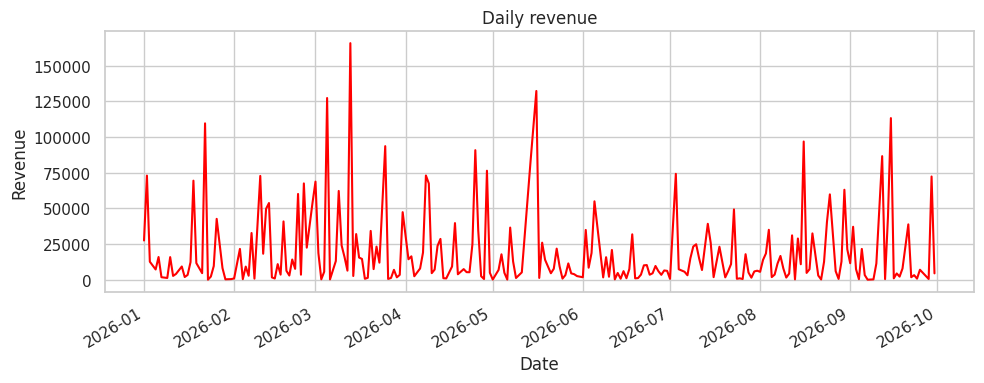

In [ ]:
fig, ax=plt.subplots(figsize=(10,4))
ax.set_title("Daily revenue")
ax.set_xlabel("Date")
ax.set_ylabel("Revenue")
ax.plot(daily["date"],daily["revenue"],color="red")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

**Bar Chart**

In [ ]:
channel_revenue=df.groupby("channel",as_index=False)["revenue"].sum()

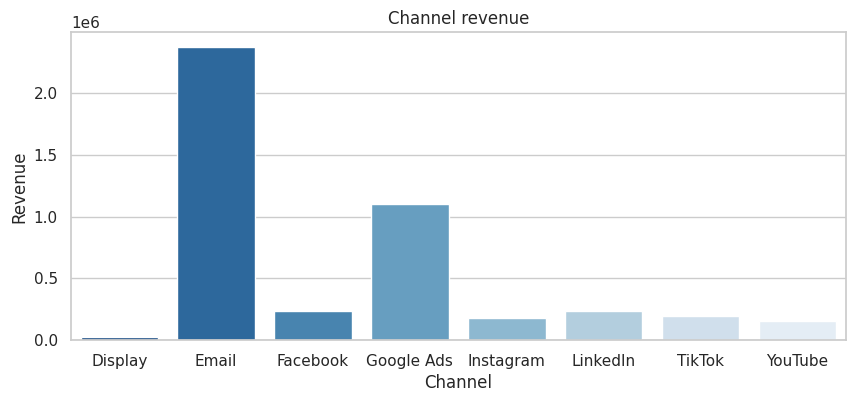

In [ ]:
fig, ax=plt.subplots(figsize=(10,4))
ax.set_title("Channel revenue")
ax.set_xlabel("Channel")
ax.set_ylabel("Revenue")
sns.barplot(data=channel_revenue,x="channel",y="revenue",ax=ax,palette="Blues_r",hue="channel",legend=False)
plt.show()

In [ ]:
by_ch_rg=df.groupby(["channel","region"],as_index=False)["revenue"].sum()

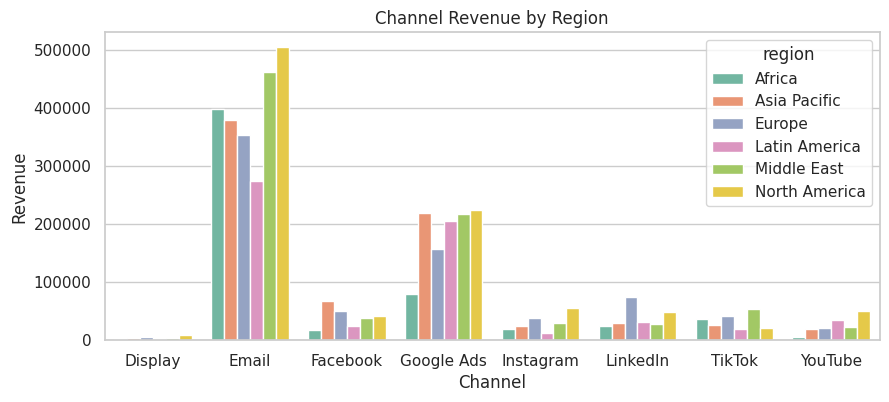

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.set_title("Channel Revenue by Region")
ax.set_xlabel("Channel")
ax.set_ylabel("Revenue")

sns.barplot(
    data=by_ch_rg,
    x="channel",
    y="revenue",
    hue="region",
    ax=ax,
    palette="Set2"
)

plt.show()

**Scatter Chart**

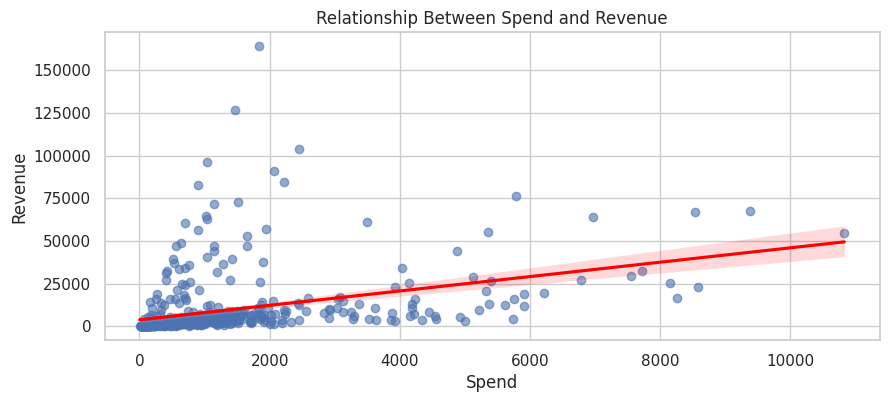

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.regplot(
    data=df,
    x="spend",
    y="revenue",
    ax=ax,
    line_kws={"color": "red"},
    scatter_kws={"alpha": 0.6}
)

ax.set_title("Relationship Between Spend and Revenue")
ax.set_xlabel("Spend")
ax.set_ylabel("Revenue")

plt.show()

In [ ]:
print(daily.columns.tolist())


['date', 'revenue']


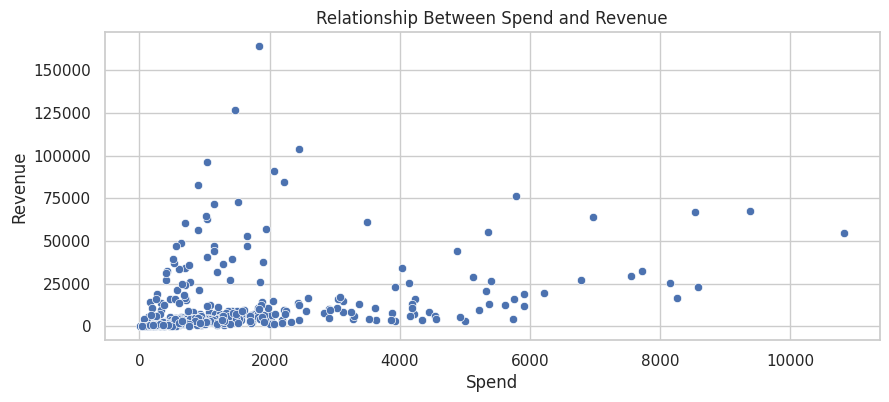

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.scatterplot(
    data=df,
    x="spend",
    y="revenue",
    ax=ax
)

ax.set_title("Relationship Between Spend and Revenue")
ax.set_xlabel("Spend")
ax.set_ylabel("Revenue")

plt.show()

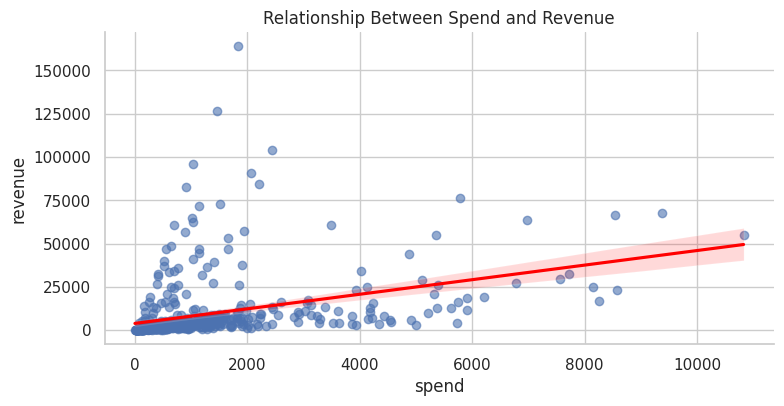

In [ ]:
sns.lmplot(
    data=df,
    x="spend",
    y="revenue",
    height=4,
    aspect=2,
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("Relationship Between Spend and Revenue")
plt.show()

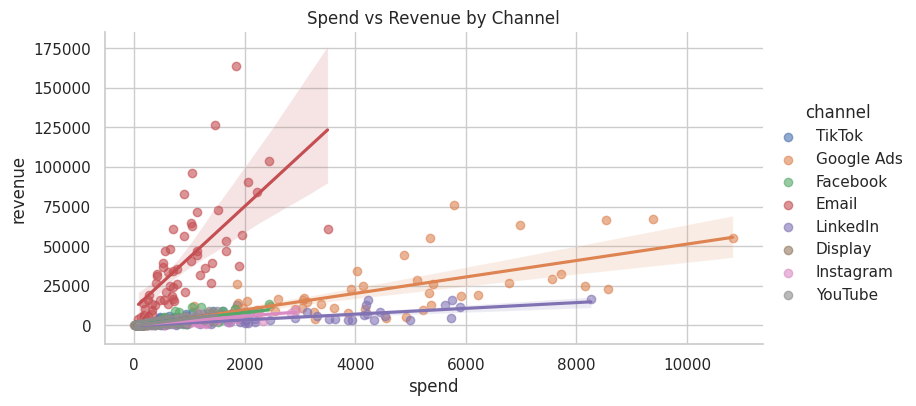

In [ ]:
sns.lmplot(
    data=df,
    x="spend",
    y="revenue",
    hue="channel",
    height=4,
    aspect=2,
    scatter_kws={"alpha": 0.6}
)

plt.title("Spend vs Revenue by Channel")
plt.show()


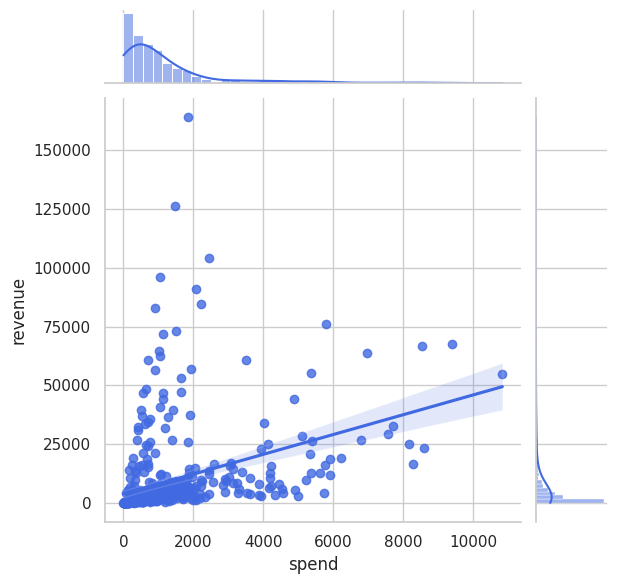

In [ ]:
sns.jointplot(
    data=df,
    x="spend",
    y="revenue",
    kind="reg",
    height=6,
    color="royalblue"
)

plt.show()


**Histogram**

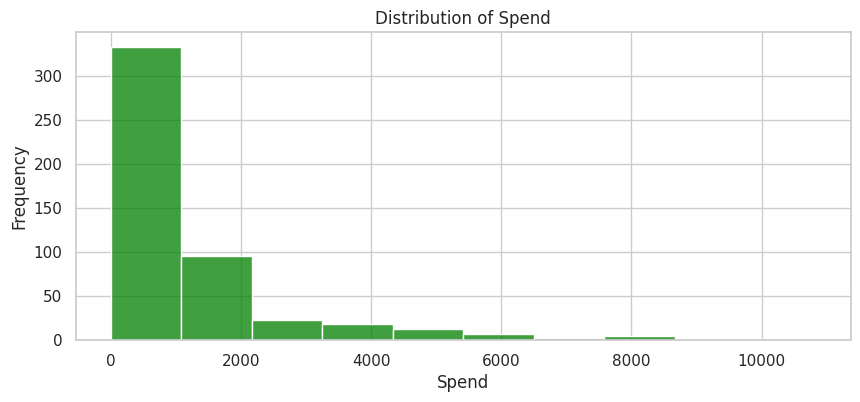

In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
ax.set_title("Distribution of Spend")
ax.set_xlabel("Spend")
ax.set_ylabel("Frequency")
sns.histplot(data=df,x="spend",ax=ax,color="green",bins=10)
plt.show()

In [ ]:
daily_con=df.groupby("date",as_index=False)["conversations"].sum()

In [ ]:
df.columns

Index(['campaign_id', 'date', 'channel', 'region', 'impression', 'clicks',
       'conversations', 'spend', 'revenue'],
      dtype='object')

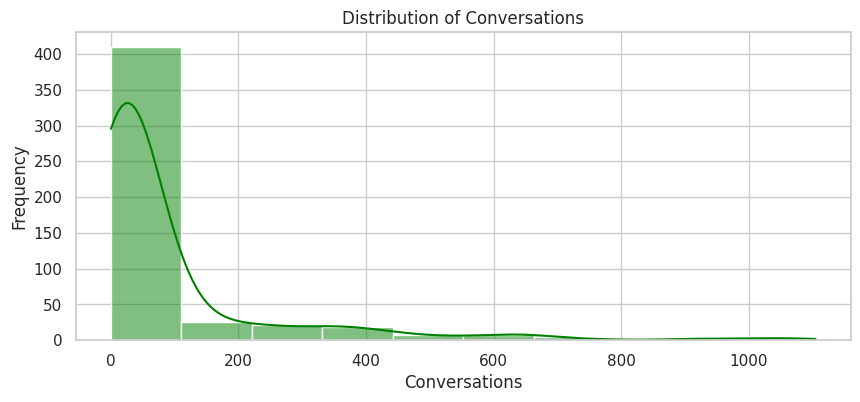

In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
ax.set_title("Distribution of Conversations")
ax.set_xlabel("Conversations")
ax.set_ylabel("Frequency")
sns.histplot(data=df,x="conversations",ax=ax,color="green",bins=10,kde=True)
plt.show()

**Boxplot**

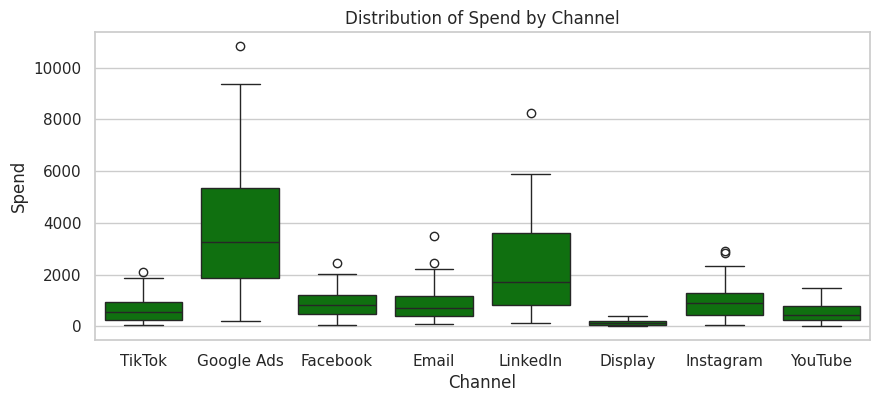

In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
ax.set_title("Distribution of Spend by Channel")
ax.set_xlabel("Channel")
ax.set_ylabel("Spend")
sns.boxplot(data=df,x="channel",y="spend",ax=ax,color="green")
plt.show()

**Correlation Heatmap**

In [ ]:
cols=["impression","clicks","conversations","spend","revenue"]
corr=df[cols].corr()

In [ ]:
corr

,impression,clicks,conversations,spend,revenue
impression,1.000000,0.493366,0.328114,0.435095,0.308824
clicks,0.493366,1.000000,0.901005,0.496680,0.824118
conversations,0.328114,0.901005,1.000000,0.355273,0.880838
spend,0.435095,0.496680,0.355273,1.000000,0.374354
revenue,0.308824,0.824118,0.880838,0.374354,1.000000


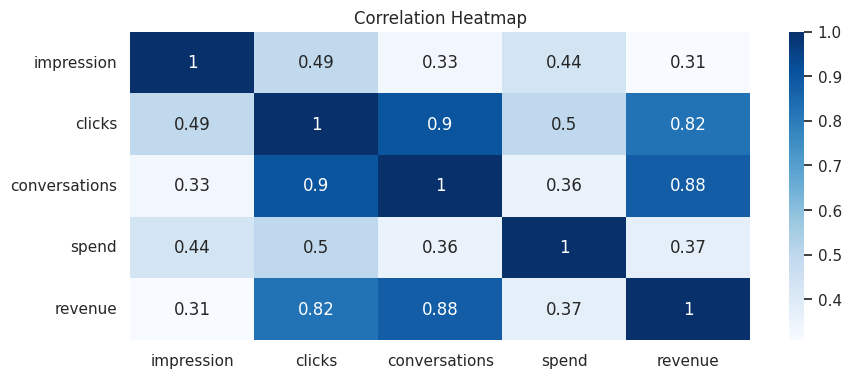

In [ ]:
fig,ax=plt.subplots(figsize=(10,4))
ax.set_title("Correlation Heatmap")
sns.heatmap(corr,annot=True,cmap="Blues",ax=ax)
plt.show()

**Subplots**

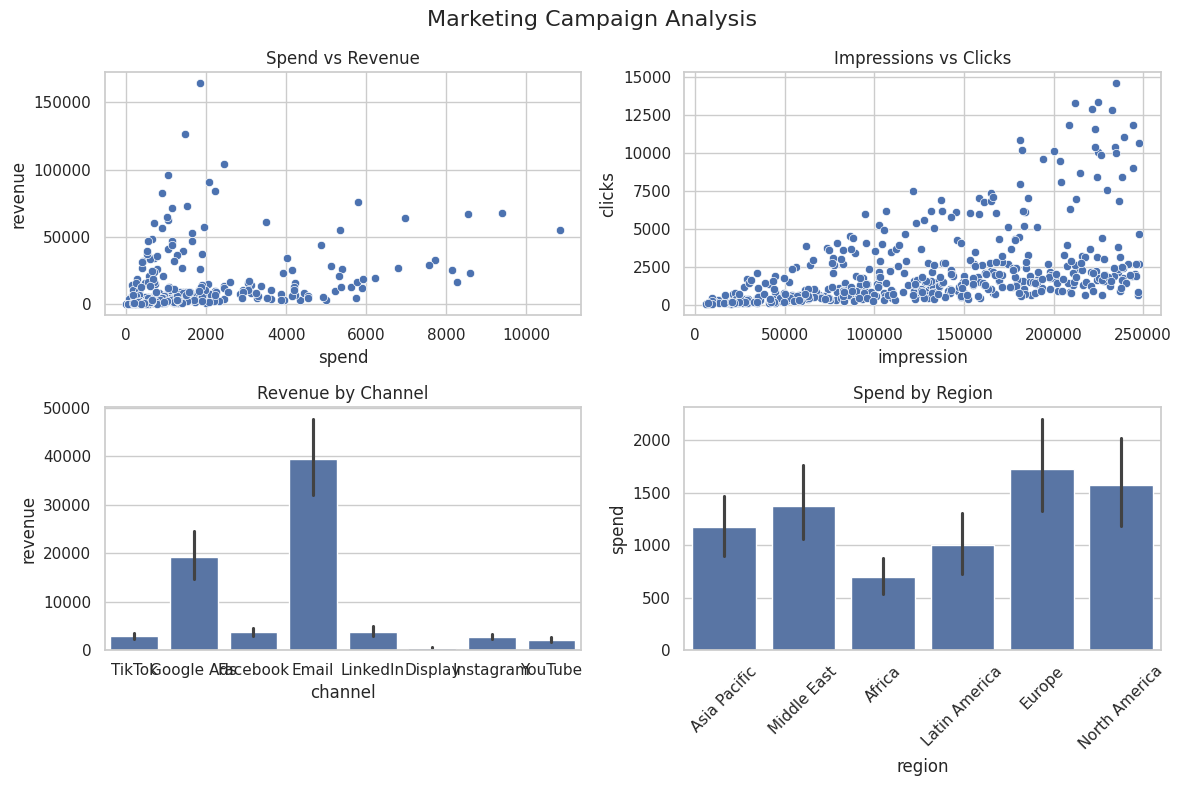

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

fig.suptitle("Marketing Campaign Analysis", fontsize=16)

# Plot 1: Spend vs Revenue
sns.scatterplot(data=df, x="spend", y="revenue", ax=axes[0, 0])
axes[0, 0].set_title("Spend vs Revenue")

# Plot 2: Impressions vs Clicks
sns.scatterplot(data=df, x="impression", y="clicks", ax=axes[0, 1])
axes[0, 1].set_title("Impressions vs Clicks")

plt.xticks(rotation=45)
# Plot 3: Revenue by Channel
sns.barplot(data=df, x="channel", y="revenue", ax=axes[1, 0])
axes[1, 0].set_title("Revenue by Channel")
plt.xticks(rotation=45)

# Plot 4: Spend by Region
sns.barplot(data=df, x="region", y="spend", ax=axes[1, 1])
axes[1, 1].set_title("Spend by Region")

plt.tight_layout()
plt.show()